# 04. Lab-to-Field Generalization Analysis

## 1. Objective

Compare frozen **ResNet18** and **ViT-Small** classifiers across the same five tomato categories on PlantVillage (Lab Test) and PlantDoc (Field Test).

The analysis focuses on cross-domain performance, class-level errors, prediction confidence, and paired differences between models. **No model training or checkpoint selection is performed in this notebook.**

### Evaluation caveats

- The original PlantDoc test subset includes only 47 images across five classes.
- Some PlantDoc images contain non-field-like backgrounds, watermarks, or text.
- Because field results are already being inspected, further model or augmentation selection using this test set would compromise its role as an untouched final benchmark. Use a separate development set for any subsequent tuning.


## 2. Load Saved Evaluation Outputs

Run this notebook **locally** from VS Code. The predictions and summary CSVs must already be generated by the evaluation scripts and stored under `outputs/resnet18_domain_gap/` and `outputs/vit_small_domain_gap/`. This analysis only reads those CSVs; no GPU is required.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score
from scipy.stats import binomtest

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "data" / "splits" / "label_map.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks/ after creating data/splits/label_map.json")

OUTPUT_DIR = ROOT / "outputs" / "comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

label_map = json.loads((ROOT / "data" / "splits" / "label_map.json").read_text())
CLASS_NAMES = [name for name, idx in sorted(label_map.items(), key=lambda x: x[1])]
MODELS = {"ResNet18": "resnet18_domain_gap", "ViT-Small": "vit_small_domain_gap"}
PREDICTIONS = {}

for model, folder in MODELS.items():
    for partition in ("lab_test", "field_test"):
        path = ROOT / "outputs" / folder / f"{partition}_predictions.csv"
        if not path.exists():
            raise FileNotFoundError(f"Missing {path}. Place evaluation outputs in the folder above.")
        PREDICTIONS[(model, partition)] = pd.read_csv(path)
        print(f"{model:9s} / {partition:10s}: {len(PREDICTIONS[(model, partition)]):,} images")

ResNet18  / lab_test  : 1,692 images
ResNet18  / field_test: 47 images
ViT-Small / lab_test  : 1,692 images
ViT-Small / field_test: 47 images


## 3. Validate Paired Evaluation Data

Both models must evaluate precisely the **same source images with the same true labels**. A fair comparison is not possible if image IDs or labels differ.

In [2]:
for partition in ("lab_test", "field_test"):
    reference = None
    for model in MODELS:
        frame = PREDICTIONS[(model, partition)]
        required = {"source", "row_id", "label_id", "predicted_label_id", "confidence"}
        assert required <= set(frame.columns), f"Missing columns: {required - set(frame.columns)}"
        assert not frame.duplicated(["source", "row_id"]).any()
        assert frame["label_id"].between(0, 4).all()
        assert frame["predicted_label_id"].between(0, 4).all()
        frame = frame.sort_values(["source", "row_id"]).reset_index(drop=True)
        PREDICTIONS[(model, partition)] = frame
        signature = frame[["source", "row_id", "label_id"]]
        if reference is None:
            reference = signature
        else:
            pd.testing.assert_frame_equal(reference, signature)

print("Passed: identical image IDs and true labels for both models in each test set.")

Passed: identical image IDs and true labels for both models in each test set.


## 4. Aggregate Test Performance

Macro-F1 gives equal weight to all classes, which is important because class counts differ. The domain gap is defined as `Lab Test Macro-F1 − Field Test Macro-F1`.

In [3]:
rows = []
for model in MODELS:
    result = {"Model": model}
    for partition, name in (("lab_test", "Lab"), ("field_test", "Field")):
        frame = PREDICTIONS[(model, partition)]
        actual, predicted = frame["label_id"], frame["predicted_label_id"]
        result[f"{name} Images"] = len(frame)
        result[f"{name} Accuracy"] = accuracy_score(actual, predicted)
        result[f"{name} Macro-F1"] = f1_score(actual, predicted, labels=range(5), average="macro", zero_division=0)
    result["Macro-F1 Gap"] = result["Lab Macro-F1"] - result["Field Macro-F1"]
    rows.append(result)
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "cnn_vs_vit_metrics.csv")

,Lab Images,Lab Accuracy,Lab Macro-F1,Field Images,Field Accuracy,Field Macro-F1,Macro-F1 Gap
Model,,,,,,,
ResNet18,1692,0.9793,0.9744,47,0.3617,0.2802,0.6942
ViT-Small,1692,0.9947,0.9938,47,0.4468,0.3617,0.6321


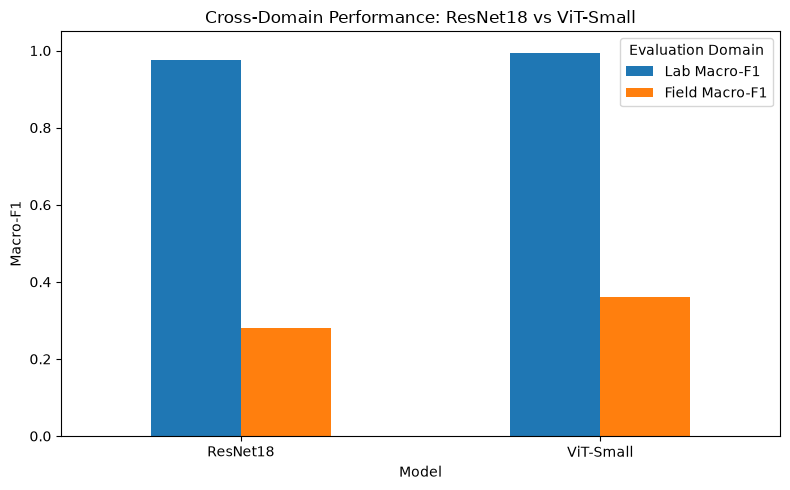

In [4]:
axes = comparison[["Lab Macro-F1", "Field Macro-F1"]].plot(kind="bar", rot=0, figsize=(8, 5), ylim=(0, 1.05))
axes.set_ylabel("Macro-F1")
axes.set_title("Cross-Domain Performance: ResNet18 vs ViT-Small")
axes.legend(title="Evaluation Domain")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "macro_f1_lab_vs_field.png", dpi=160)
plt.show()

## 5. Per-Class Field Recall

Recall measures the fraction of actual images belonging to each disease category that the model correctly recognizes. This highlights classes with critical failure modes.

Model,ResNet18,ViT-Small
Disease,,
Healthy,0.0000,0.1250
Early Blight,0.6667,0.5556
Late Blight,0.5000,0.7000
Bacterial Spot,0.0000,0.0000
Septoria Leaf Spot,0.5455,0.7273


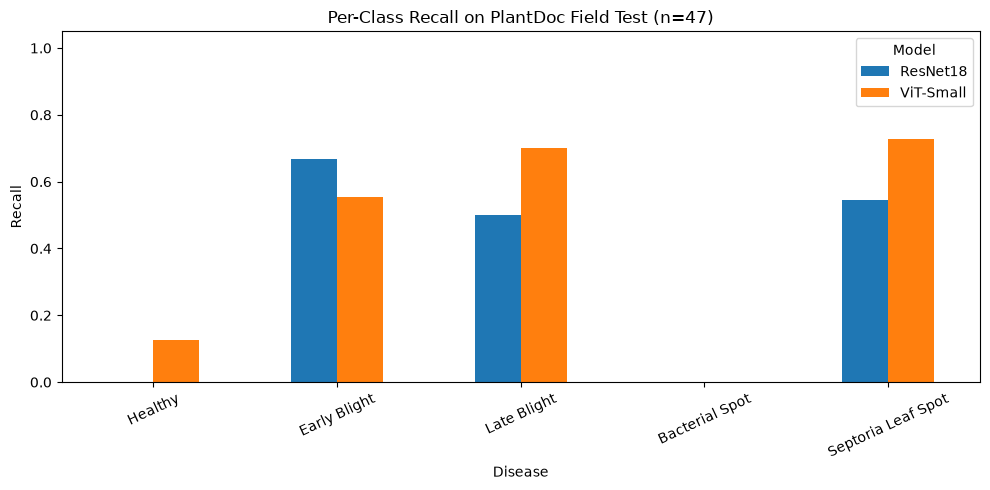

In [5]:
recall_rows = []
for model in MODELS:
    frame = PREDICTIONS[(model, "field_test")]
    per_class = recall_score(frame["label_id"], frame["predicted_label_id"], labels=range(5), average=None, zero_division=0)
    for class_name, recall in zip(CLASS_NAMES, per_class):
        recall_rows.append({"Model": model, "Disease": class_name, "Recall": recall})
recall_df = pd.DataFrame(recall_rows)
recall_pivot = recall_df.pivot(index="Disease", columns="Model", values="Recall").reindex(CLASS_NAMES)
display(recall_pivot.round(4))
ax = recall_pivot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=25)
ax.set_ylabel("Recall")
ax.set_title("Per-Class Recall on PlantDoc Field Test (n=47)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "field_per_class_recall.png", dpi=160)
plt.show()

## 6. Paired Error Analysis and Confidence

Compare predictions on identical Field Test images. Count images that both models classify correctly, that only one model classifies correctly, or that neither recognizes. Confidence refers to the maximum softmax score and **is not a calibrated probability of correctness**.

In [6]:
field_resnet = PREDICTIONS[("ResNet18", "field_test")]
field_vit = PREDICTIONS[("ViT-Small", "field_test")]
r_correct = field_resnet["label_id"].eq(field_resnet["predicted_label_id"]).to_numpy()
v_correct = field_vit["label_id"].eq(field_vit["predicted_label_id"]).to_numpy()
counts = {
    "Both correct": int(np.sum(r_correct & v_correct)),
    "Only ResNet18 correct": int(np.sum(r_correct & ~v_correct)),
    "Only ViT-Small correct": int(np.sum(~r_correct & v_correct)),
    "Both incorrect": int(np.sum(~r_correct & ~v_correct)),
}
display(pd.Series(counts, name="Images").to_frame())
# Exploratory paired significance test; small test sample limits conclusions.
only_r, only_v = counts["Only ResNet18 correct"], counts["Only ViT-Small correct"]
print("McNemar exact p-value:", round(binomtest(only_r, only_r + only_v, p=0.5).pvalue, 4))

confidence_rows = []
for model, frame in (("ResNet18", field_resnet), ("ViT-Small", field_vit)):
    wrong = frame[frame["label_id"] != frame["predicted_label_id"]]
    confidence_rows.append({
        "Model": model, "Wrong predictions": len(wrong),
        "Wrong with confidence ≥ 0.90": int((wrong["confidence"] >= 0.90).sum()),
        "Wrong with confidence ≥ 0.99": int((wrong["confidence"] >= 0.99).sum()),
    })
display(pd.DataFrame(confidence_rows).set_index("Model"))

,Images
Both correct,13
Only ResNet18 correct,4
Only ViT-Small correct,8
Both incorrect,22


McNemar exact p-value: 0.3877


,Wrong predictions,Wrong with confidence ≥ 0.90,Wrong with confidence ≥ 0.99
Model,,,
ResNet18,30,21,9
ViT-Small,26,11,4


In [7]:
# Export paired predictions for qualitative review.
paired = field_resnet[["source", "row_id", "class_name", "label_id"]].copy()
for model, frame, prefix in (("ResNet18", field_resnet, "resnet"), ("ViT-Small", field_vit, "vit")):
    paired[f"{prefix}_predicted_class"] = frame["predicted_class"]
    paired[f"{prefix}_confidence"] = frame["confidence"]
    paired[f"{prefix}_correct"] = frame["label_id"].eq(frame["predicted_label_id"])
paired.to_csv(OUTPUT_DIR / "paired_field_predictions.csv", index=False)
print("Saved paired predictions to:", OUTPUT_DIR / "paired_field_predictions.csv")

Saved paired predictions to: /Volumes/Lexar E6/Code/plant-disease-diagnosis/outputs/comparison/paired_field_predictions.csv


## 7. Interpretation and Research Next Steps

**Observed results (current baseline):** ViT-Small achieves higher macro-F1 than ResNet18 on both laboratory and field test data. Both models suffer a large Lab-to-Field performance drop. Neither model correctly recognizes the Bacterial Spot examples in the 47-image field test.

**Important limitations:** These are comparisons between two specific pretrained architectures, not proof that Transformers generalize better than CNNs overall. The Field Test set is small and heterogeneous. Repeatedly changing models based on this test set would cause test-set overfitting.

**Next experiments:**

1. Conduct qualitative error analysis on field training/development images and review label quality and visual artifacts without editing the held-out test labels.
2. Develop lab-only augmentation experiments using **Lab Validation** for model selection; do not select augmentation by Field Test results.
3. For supervised field adaptation, split the original **PlantDoc training partition** into development-train and development-validation data; keep the original field test fixed.
4. Evaluate final selected models on an additional independently collected, labeled real-field test set if possible.
